# Figure 3 — FFPE and tumour-only somatic profiles

Panels **A–C** compare **fresh-frozen (FF)** with **FFPE** tumour/normal Illumina WGS for two
patient samples (shown with consent); panels **D–E** compare **tumour/normal (TN)** with
**tumour-only (TO)** Illumina WGS across the five cell lines. All from filtered (PASS) PURPLE
output.

| Panel | Content |
|-------|---------|
| **A** | Variant burden — SNV, MNV, indel, SV, CNA (FF vs FFPE) |
| **B** | SV class composition (FF vs FFPE) |
| **C** | PURPLE circos with tumour purity, and the reportable-driver oncoprint (FF vs FFPE) |
| **D** | Variant burden (Illumina TN vs TO), tumour-only small variants split by somatic likelihood |
| **E** | SV class composition (Illumina TN vs TO) |

Point the Configuration cell at other runs — or your own oncoanalyser output — and run all
cells; see **Data access** below.

## Data access

Every input below is public **oncoanalyser** output, published in two Google Cloud Storage
buckets. Nothing else is needed to reproduce this figure.

| Bucket | Content | Size |
| --- | --- | --- |
| `gs://hartwig-oapaper-celllines` | 5 cell lines x 3 sequencing platforms, WGS and targeted panel | 36 GB |
| `gs://hartwig-oapaper-patients` | 2 consented patients, fresh-frozen and FFPE WGS, targeted panel | — |

### Folder scheme

Every pipeline run has one folder, built from the same fields in the same order —
**sample, modality, platform, aligner, run type, pipeline**:

```text
gs://hartwig-oapaper-celllines/<sample>/<modality>/<platform>/<aligner>/<run type>/<pipeline>/
gs://hartwig-oapaper-patients/<sample>/<modality>/<preservation>/<platform>/<aligner>/<run type>/<pipeline>/

<sample>        COLO829 | HCC1187 | HCC1395 | HCC1954 | HG008      cell lines
                H00005238 | H00006429                              patients
<modality>      wgs | panel                 panel = HMF oncopanel v3, Illumina only
<preservation>  ff | ffpe                   patients only
<platform>      illumina_novaseq6000 | roche_sbx | ultima_ug100
<aligner>       bwa
<run type>      tn = tumour/normal | to = tumour-only
<pipeline>      oa3 = oncoanalyser 3.x
```

So COLO829, Illumina WGS, tumour/normal is:

```text
gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

Inside `oa3/` are the oncoanalyser output directories exactly as the pipeline writes them —
`alignments/`, `bamtools/`, `purple/`, `sage/`, `linx/`, `sigs/`, `logs/`, ... — with **no**
`results/<subject>` level in between.

Sample names inside a run are *not* uniform: tumours are `<sample>T`, but normals are
`<sample>R` for COLO829, HG008 and the patients and `<sample>BL` for HCC1187/HCC1395/HCC1954,
and the Illumina COLO829 WGS run uses `COLO829v012T` / `COLO829v012R` throughout. Nothing
hard-codes them — every notebook reads the real names out of `alignments/` and `purple/`.

Browse it with:

```bash
gsutil ls gs://hartwig-oapaper-celllines/
gsutil ls gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

### What this notebook reads (~180 MB)

Fourteen run folders: 2 patients x {FF, FFPE} for panels A–C, and 5 cell lines x {TN, TO} for
panels D–E.

```text
gs://hartwig-oapaper-patients/<patient>/wgs/<ff|ffpe>/illumina_novaseq6000/bwa/tn/oa3/
gs://hartwig-oapaper-celllines/<cell line>/wgs/illumina_novaseq6000/bwa/<tn|to>/oa3/

  purple/<tumour>.purple.somatic.vcf.gz                 panels A, D   SNV / MNV / indel
  purple/<tumour>.purple.sv.vcf.gz                      panels A, B, D, E   SV classes
  purple/<tumour>.purple.cnv.somatic.tsv                panels A, D   CNA
  purple/<tumour>.purple.purity.tsv                     panels A, C   purity and ploidy
  purple/<tumour>.purple.driver.catalog.somatic.tsv     panel C       amp / del drivers
  purple/plot/<tumour>.circos.png                       panel C       circos image
  linx/somatic_annotations/<tumour>.linx.drivers.tsv    panel C       disruptions
```

Only the first four files are needed for panels D–E, so a missing `linx/` or `plot/` folder
degrades one panel rather than failing the notebook.

**The patient bucket is not yet public.** Panels A–C need read access to
`gs://hartwig-oapaper-patients`; panels D–E run from the fully public cell-line bucket alone.
If the patient runs are unreachable the loader prints a warning per sample and those panels
come out blank.

### Option 1 — read straight from the bucket (the default; nothing to download first)

Leave the `gs://` values in the Configuration cell as they are and run all cells. Only the
files listed above are staged, into `data/`, and re-used on every later run — delete that
directory to re-fetch. You need the
[Google Cloud SDK](https://cloud.google.com/sdk/docs/install) on `PATH`, authenticated once:

```bash
gcloud auth login      # any Google account works; the buckets are public, this only sets the billing/quota project
```

### Option 2 — copy the data down first, then work offline

Mirror only the run folders this notebook needs (sizes above), then repoint the
Configuration cell at the copy:

```bash
DEST=~/oapaper-data          # anywhere with enough free space
for S in H00005238 H00006429; do
  for PRES in ff ffpe; do
    gcloud storage rsync -r \
      gs://hartwig-oapaper-patients/$S/wgs/$PRES/illumina_novaseq6000/bwa/tn/oa3 \
      $DEST/patients/$S/wgs/$PRES/illumina_novaseq6000/bwa/tn/oa3
  done
done
for CL in COLO829 HCC1187 HCC1395 HCC1954 HG008; do
  for RT in tn to; do
    gcloud storage rsync -r \
      gs://hartwig-oapaper-celllines/$CL/wgs/illumina_novaseq6000/bwa/$RT/oa3 \
      $DEST/celllines/$CL/wgs/illumina_novaseq6000/bwa/$RT/oa3
  done
done          # ~10 GB for the ten complete cell-line run folders
```

Then, in the Configuration cell:

```python
CELLLINES_ROOT = "/absolute/path/to/oapaper-data/celllines"
PATIENTS_ROOT  = "/absolute/path/to/oapaper-data/patients"
```

Local paths must be **absolute** — `~` is not expanded, so `~/oapaper-data` fails with
`FileNotFoundError`. `gcloud storage rsync` is resumable: re-run it after an interruption.

### Option 3 — run it on your own oncoanalyser output

Point the Configuration cell at any oncoanalyser 3.x run directory, local or `gs://`. The
only requirement is that the directory contains the tool sub-folders listed above; the
sample names are read from the files themselves, so they do not have to match ours.


## 1 · Configuration

In [2]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# Each arm is a {sample id: run folder} map. A run folder is one oncoanalyser
# output directory — local path or gs:// URI — holding purple/, linx/ and the
# rest directly (no results/<subject> level). patient_run() and cellline_run()
# build them from the scheme described in Data access above; edit those two
# functions if your own output is laid out differently.
# ============================================================================
CELLLINES_ROOT = "gs://hartwig-oapaper-celllines"   # or an absolute path to a local copy
PATIENTS_ROOT  = "gs://hartwig-oapaper-patients"    # not yet public: panels A-C need access

PATIENT_SAMPLES   = ["H00005238", "H00006429"]
CELL_LINE_SAMPLES = ["COLO829", "HCC1187", "HCC1395", "HCC1954", "HG008"]
PLATFORM          = "illumina_novaseq6000"     # roche_sbx | ultima_ug100 for the cell lines

def patient_run(sample, preservation, run_type="tn", platform=PLATFORM):
    """<PATIENTS_ROOT>/<sample>/wgs/<ff|ffpe>/<platform>/bwa/<tn|to>/oa3"""
    return (f"{str(PATIENTS_ROOT).rstrip('/')}/{sample}/wgs/{preservation}"
            f"/{platform}/bwa/{run_type}/oa3")

def cellline_run(cell_line, run_type, platform=PLATFORM, modality="wgs"):
    """<CELLLINES_ROOT>/<cell line>/<wgs|panel>/<platform>/bwa/<tn|to>/oa3"""
    return (f"{str(CELLLINES_ROOT).rstrip('/')}/{cell_line}/{modality}"
            f"/{platform}/bwa/{run_type}/oa3")

# Panels A-C — fresh-frozen vs FFPE, both tumour/normal. FF is the reference arm.
MODALITIES = OrderedDict([
    ("FF",   {"runs":  {s: patient_run(s, "ff")   for s in PATIENT_SAMPLES},
              "color": "#22876B", "label": "Fresh-frozen (TN)"}),
    ("FFPE", {"runs":  {s: patient_run(s, "ffpe") for s in PATIENT_SAMPLES},
              "color": "#754275", "label": "FFPE (TN)"}),
])
# Panels D-E — Illumina cell lines, tumour/normal vs tumour-only.
CONDITIONS = OrderedDict([
    ("TN", {"runs":  {c: cellline_run(c, "tn") for c in CELL_LINE_SAMPLES},
            "label": "Tumor / Normal"}),
    ("TO", {"runs":  {c: cellline_run(c, "to") for c in CELL_LINE_SAMPLES},
            "label": "Tumor-only"}),
])
ILLUMINA_COLOR = "#E08214"
# ============================================================================

LOSS_MAX_CN = 0.5      # CNA: deep loss if copyNumber <= this
GAIN_MULT   = 3.0      # CNA: high gain if copyNumber >= GAIN_MULT * ploidy
VAF_MIN     = 0.10     # small variants are counted only above this tumour FORMAT AF

# Downloaded inputs are cached under data/figure_3/<run-folder>/, keyed on the folders above,
# so switching runs re-fetches rather than reusing the previous run's files. Delete to refresh.
CACHE_ROOT = Path("data") / "figure_3"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)
for _name, _cfg in [*MODALITIES.items(), *CONDITIONS.items()]:
    print(f"{_name:5s} {len(_cfg['runs'])} run(s), e.g. {next(iter(_cfg['runs'].values()))}")

FF    2 run(s), e.g. gs://hartwig-oapaper-patients/H00005238/wgs/ff/illumina_novaseq6000/bwa/tn/oa3
FFPE  2 run(s), e.g. gs://hartwig-oapaper-patients/H00005238/wgs/ffpe/illumina_novaseq6000/bwa/tn/oa3
TN    5 run(s), e.g. gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3
TO    5 run(s), e.g. gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/to/oa3


## 2 · Locating pipeline output

Turns each `{sample: run folder}` map from the Configuration cell into the tumour sample names
the loaders need, and provides the local / `gs://` read helpers. Nothing is downloaded here.

In [3]:
import subprocess, re, hashlib
from pathlib import Path

# ---- IO: identical behaviour for local paths and gs:// URIs -----------------------------------
# Every gsutil call goes through _gsutil, which returns None when the target simply does not exist
# and raises on anything else (auth, permissions, typo'd bucket). A silent [] on a failed listing
# is what makes a missing-data problem look like an empty-run problem.
_MISSING = ("matched no objects", "no urls matched", "404")

def _is_remote(p):
    return str(p).startswith("gs://")

def _gsutil(*args):
    r = subprocess.run(["gsutil", *map(str, args)], capture_output=True, text=True)
    if r.returncode != 0:
        err = r.stderr.strip()
        if any(m in err.lower() for m in _MISSING):
            return None
        raise RuntimeError(f"gsutil {' '.join(map(str, args))} failed:\n{err}")
    return r.stdout

_GLOB_CACHE = {}   # listings are memoised for the session; clear it if a run folder changes

def _glob(folder, pattern, dirs_only=True):
    # Entries matching folder/pattern, without a trailing slash. '*' never crosses a '/'.
    key = (str(folder).rstrip("/"), pattern, dirs_only)
    if key not in _GLOB_CACHE:
        _GLOB_CACHE[key] = _glob_uncached(*key)
    return _GLOB_CACHE[key]

def _glob_uncached(folder, pattern, dirs_only):
    if _is_remote(folder):
        out = _gsutil("ls", "-d", f"{str(folder).rstrip('/')}/{pattern}")
        hits = [l for l in (out or "").splitlines() if l.strip()]
        if dirs_only:
            hits = [h for h in hits if h.endswith("/")]
        return sorted(h.rstrip("/") for h in hits)
    return sorted(str(p) for p in Path(folder).glob(pattern) if p.is_dir() or not dirs_only)

def _fetch(src, dest):
    # Copy one file into the local cache. Returns None (not an exception) when the source is
    # absent, so a run that skipped a step degrades to a blank panel instead of a crash.
    dest = Path(dest)
    if dest.exists():
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    if _is_remote(src):
        if _gsutil("cp", str(src), str(dest)) is None:
            return None
    else:
        if not Path(src).exists():
            return None
        import shutil; shutil.copy(Path(src), dest)
    return dest

def cache_dir(root, folder, *parts):
    """Local cache path, keyed on the source folder.

    Two runs of the same arm live in different directories, so re-pointing a folder never
    silently reuses the previous run's downloaded files.
    """
    src = str(folder).rstrip("/")
    tail = [p for p in src.split("//")[-1].split("/") if p][-6:]   # readable, still unambiguous
    label = re.sub(r"[^A-Za-z0-9]+", "-", "-".join(tail)).strip("-")
    return Path(root, f"{label}-{hashlib.sha1(src.encode()).hexdigest()[:6]}", *parts)

# ---- Subject discovery ------------------------------------------------------------------------
# In this layout a run folder *is* the subject directory: purple/, alignments/, bamtools/, logs/
# and the rest sit directly inside it, with no results/<subject> level. Sample names are still
# read out of the output rather than assumed, so runs whose samples are named differently
# (COLO829v012T, HCC1187BL, ...) need no configuration. PURPLE output is the marker, because
# runs started from pre-existing BAMs do not always republish an alignments/ folder.
_PURITY_SUFFIX = ".purple.purity.tsv"

def find_tumour(base):
    """Tumour sample name of one run folder, from <base>/purple/<tumour>.purple.purity.tsv.

    Returns None when the run simply has no PURPLE output, and raises when the location cannot
    be read at all (no credentials, no access, wrong bucket). Callers turn that into a single
    warning for the whole arm, so a permissions problem is never mistaken for an empty run.
    """
    hits = _glob(base, f"purple/*{_PURITY_SUFFIX}", dirs_only=False)
    return hits[0].rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)] if hits else None

def _unreadable(base, err):
    print(f"WARN: cannot read {base}\n      {str(err).strip().splitlines()[-1]}")

def discover_subjects(runs):
    """[(sid, tumour_sample, base), ...] for a {sid: run folder} map, in configured order."""
    found = []
    for sid, base in runs.items():
        try:
            tumor = find_tumour(base)
        except RuntimeError as e:      # the whole location is unreadable, not just this run
            _unreadable(base, e)
            break
        if tumor is None:
            print(f"WARN: no PURPLE output under {base}/purple/ -- skipping {sid}")
            continue
        found.append((sid, tumor, base))
    return found

print("path helpers ready")

path helpers ready


## 3 · Plotting style

In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.titleweight": "bold",
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

VAR_TYPES = ["SNV", "MNV", "indel", "SV", "CNA"]
SV_ORDER  = ["DEL", "DUP", "INS", "INV", "BND", "SGL"]
SV_COLORS = {"DEL": "#4C72B0", "DUP": "#DD8452", "INS": "#55A868",
             "INV": "#C44E52", "BND": "#8172B3", "SGL": "#937860"}

# Reportable-driver categories, in the left-to-right order of the panel C oncoprint.
CAT_ORDER  = ["disruption", "del", "amp", "indel", "snv"]
CAT_COLORS = {"disruption": "#CC79A7", "del": "#009E73", "amp": "#D55E00",
              "indel": "#E69F00", "snv": "#0072B2"}

TO_TINT = 0.62   # tumour-only bars are this far towards white from their tumour/normal colour

def _lighten(color, amt=TO_TINT):
    r, g, b = mpl.colors.to_rgb(color)
    return (r + (1 - r) * amt, g + (1 - g) * amt, b + (1 - b) * amt)

def _cond_face(base, cond):
    return base if cond == "TN" else _lighten(base)

# Panel D — tumour-only per-variant somatic likelihood (SOM_LH), as shades of the Illumina orange:
# HIGH darker than the tumour/normal bar, MEDIUM and LOW progressively lighter tints.
SOMLH_STACK  = ["HIGH", "MEDIUM", "LOW", "NA"]     # NA (grey) is drawn only when present
SOMLH_COLORS = {"HIGH": "#9A520A", "MEDIUM": _lighten(ILLUMINA_COLOR, 0.40),
                "LOW": _lighten(ILLUMINA_COLOR, 0.80), "NA": "#CFCFCF"}

def _text_color(facecolor):
    r, g, b = mpl.colors.to_rgb(facecolor)
    return "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.55 else "white"

def _short(cl):
    if cl.startswith("HCC"):
        return cl[3:]
    if cl.startswith("COLO"):
        return "COLO"
    return cl

## 4 · Load PURPLE output — FF vs FFPE (panels A–C)

Per arm and patient: SNV/MNV/indel counts (VAF ≥ 10%), SV class counts, copy-number-altered segment
count, tumour purity, the reportable drivers (PURPLE `REPORTED` point variants + amp/del driver
catalog + LINX disruptions) and the PURPLE circos PNG.

In [5]:
import gzip
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.image as mpimg

AMP_DRIVERS = {"AMP", "PARTIAL_AMP"}

def _tumor_vaf(fmt_field, sample):
    # Observed tumour VAF = FORMAT AF of the tumour (last) sample column.
    keys = fmt_field.split(":")
    if "AF" not in keys:
        return np.nan
    try:
        return float(sample.split(":")[keys.index("AF")])
    except (ValueError, IndexError):
        return np.nan

def parse_small_variants(path):
    # PASS SNV/MNV/indel counts, restricted to tumour VAF >= VAF_MIN, plus the same counts split
    # by SOM_LH ('NA' where the field is absent, i.e. every tumour/normal call).
    counts = {"SNV": 0, "MNV": 0, "indel": 0}
    somlh = {vt: Counter() for vt in counts}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            vaf = _tumor_vaf(c[8], c[-1])
            if np.isnan(vaf) or vaf < VAF_MIN:
                continue
            rl, al = len(c[3]), len(c[4].split(",")[0])
            vt = "SNV" if (rl == 1 and al == 1) else ("MNV" if rl == al else "indel")
            counts[vt] += 1
            m = re.search(r"(?:^|;)SOM_LH=([A-Z]+)", c[7])
            somlh[vt][m.group(1) if m else "NA"] += 1
    return counts, somlh

def parse_sv(path):
    cnt = Counter()
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.split("\t")
            if c[6] != "PASS":
                continue
            m = re.search(r"SVTYPE=([A-Z]+)", c[7])
            if m:
                cnt[m.group(1)] += 1
    return dict(cnt)

def parse_cna(path, ploidy):
    cn = pd.read_csv(path, sep="\t")["copyNumber"]
    return int(((cn <= LOSS_MAX_CN) | (cn >= GAIN_MULT * ploidy)).sum())

def parse_reported(path):
    # (gene, category) for REPORTED PASS point variants; gene from the INFO IMPACT field.
    out = []
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS" or not re.search(r"(?:^|;)REPORTED(?:;|$)", c[7]):
                continue
            rl, al = len(c[3]), len(c[4].split(",")[0])
            if rl == al and rl != 1:            # MNVs are not shown in the oncoprint
                continue
            m = re.search(r"(?:^|;)IMPACT=([^;,]+)", c[7])
            out.append((m.group(1) if m else ".", "snv" if rl == 1 else "indel"))
    return out

def parse_cn_drivers(path):
    df = pd.read_csv(path, sep="\t")
    rep = df[df["reportedStatus"] == "REPORTED"]
    return [(g, "amp" if d in AMP_DRIVERS else "del") for g, d in zip(rep["gene"], rep["driver"])
            if d in AMP_DRIVERS or d == "DEL"]

def parse_disruptions(path):
    df = pd.read_csv(path, sep="\t")
    return [(g, "disruption") for g, ev in zip(df["gene"], df["eventType"]) if "DISRUPTION" in str(ev)]

def _purple_core(base, tumor, dest):
    # The four PURPLE files every panel needs; None if any of them is missing.
    want = {"som": f"{base}/purple/{tumor}.purple.somatic.vcf.gz",
            "sv":  f"{base}/purple/{tumor}.purple.sv.vcf.gz",
            "cnv": f"{base}/purple/{tumor}.purple.cnv.somatic.tsv",
            "pur": f"{base}/purple/{tumor}.purple.purity.tsv"}
    got = {k: _fetch(v, dest / v.rsplit("/", 1)[-1]) for k, v in want.items()}
    absent = [want[k].rsplit("/", 1)[-1] for k, v in got.items() if v is None]
    if absent:
        print(f"WARN: skipping {tumor} -- missing PURPLE output: {', '.join(absent)}")
        return None
    return got

def _burden(got):
    pur = pd.read_csv(got["pur"], sep="\t")
    counts, somlh = parse_small_variants(got["som"])
    svc = parse_sv(got["sv"])
    counts["SV"] = int(sum(svc.values()))            # SV and CNA have no per-allele VAF
    counts["CNA"] = parse_cna(got["cnv"], float(pur["ploidy"].iloc[0]))
    return counts, svc, float(pur["purity"].iloc[0]), somlh

def load_arm_sample(base, tumor, dest):
    got = _purple_core(base, tumor, dest)
    if got is None:
        return None
    counts, svc, purity, _ = _burden(got)
    dc   = _fetch(f"{base}/purple/{tumor}.purple.driver.catalog.somatic.tsv",
                  dest / f"{tumor}.driver.catalog.somatic.tsv")
    lx   = _fetch(f"{base}/linx/somatic_annotations/{tumor}.linx.drivers.tsv",
                  dest / f"{tumor}.linx.drivers.tsv")
    circ = _fetch(f"{base}/purple/plot/{tumor}.circos.png", dest / f"{tumor}.circos.png")
    drivers = set(parse_reported(got["som"]))
    if dc is not None:
        drivers |= set(parse_cn_drivers(dc))
    if lx is not None:
        drivers |= set(parse_disruptions(lx))
    return {"counts": counts, "sv": svc, "purity": purity, "drivers": drivers,
            "circos": str(circ) if circ else None}

ARM = {}
for m in MODALITIES:
    ARM[m] = {}
    for sid, tumor, base in discover_subjects(MODALITIES[m]["runs"]):
        s = load_arm_sample(base, tumor, cache_dir(CACHE_ROOT, base, sid))
        if s is not None:
            ARM[m][sid] = s
    print(f"{m}: " + ", ".join(f"{s} purity={ARM[m][s]['purity']:.0%} "
                               f"drivers={len(ARM[m][s]['drivers'])}" for s in ARM[m]))

PATIENTS = sorted(set().union(*[set(ARM[m]) for m in MODALITIES]))
TRUTH, TEST = list(MODALITIES)
print("patients:", PATIENTS)

FF: H00005238 purity=54% drivers=12, H00006429 purity=66% drivers=7
FFPE: H00005238 purity=20% drivers=8, H00006429 purity=89% drivers=5
patients: ['H00005238', 'H00006429']


## 5 · Load PURPLE output — Illumina TN vs TO (panels D–E)

The same burden and SV-class parse for the Illumina cell-line panel, once per condition. A run that
does not exist yet is reported and skipped, leaving panels D–E blank rather than failing the notebook.

In [6]:
def load_cell_sample(base, tumor, dest):
    got = _purple_core(base, tumor, dest)
    if got is None:
        return None
    counts, svc, _, somlh = _burden(got)
    return {"counts": counts, "sv": svc, "somlh": somlh}

CELL = {}
for cond in CONDITIONS:
    CELL[cond] = {}
    subjects = discover_subjects(CONDITIONS[cond]["runs"])
    if not subjects:
        print(f"WARN: no PURPLE output for {cond} -- it will be blank in panels D-E")
        continue
    for cl, tumor, base in subjects:
        s = load_cell_sample(base, tumor, cache_dir(CACHE_ROOT, base, cl))
        if s is not None:
            CELL[cond][cl] = s
    print(f"{cond}: {list(CELL[cond])}")

CELL_LINES = sorted(set().union(*[set(CELL[c]) for c in CONDITIONS]))
print("cell lines:", CELL_LINES)

TN: ['COLO829', 'HCC1187', 'HCC1395', 'HCC1954', 'HG008']
TO: ['COLO829', 'HCC1187', 'HCC1395', 'HCC1954', 'HG008']
cell lines: ['COLO829', 'HCC1187', 'HCC1395', 'HCC1954', 'HG008']


## 6 · Panel A — variant burden (FF vs FFPE)

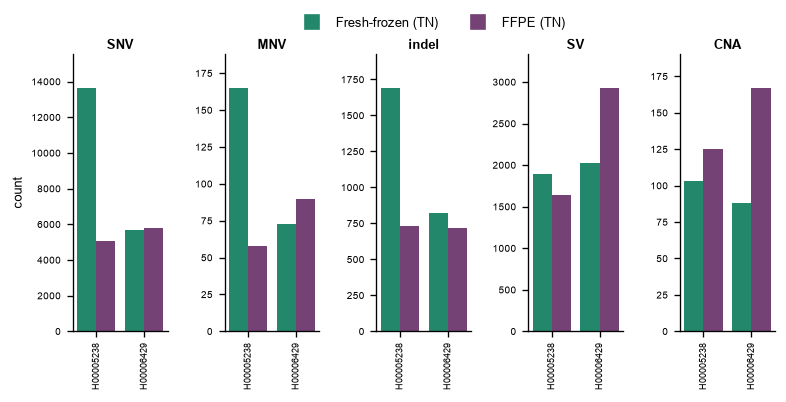

In [7]:
def draw_burden(fig, spec):
    # One sub-axes per variant class; within each, FF and FFPE side by side per patient.
    mods = list(MODALITIES); w = 0.8 / len(mods)
    x = np.arange(len(PATIENTS))
    sub = spec.subgridspec(1, len(VAR_TYPES), wspace=0.60)
    axes = []
    for k, vt in enumerate(VAR_TYPES):
        ax = fig.add_subplot(sub[0, k])
        for mi, m in enumerate(mods):
            vals = [ARM[m][s]["counts"].get(vt, np.nan) if s in ARM[m] else np.nan for s in PATIENTS]
            ax.bar(x + (mi - (len(mods) - 1) / 2) * w, vals, w,
                   color=MODALITIES[m]["color"], zorder=2)
        ax.set_title(vt, fontsize=7.5, pad=3)
        ax.set_xticks(x); ax.set_xticklabels(PATIENTS, fontsize=5.6, rotation=90)
        ax.tick_params(axis="y", labelsize=6); ax.margins(y=0.14)
        axes.append(ax)
    axes[0].set_ylabel("count")
    return axes

fig = plt.figure(figsize=(6.5, 3.4))
draw_burden(fig, fig.add_gridspec(1, 1, left=0.09, right=0.99, top=0.90, bottom=0.22)[0, 0])
fig.legend(handles=[Line2D([0], [0], marker="s", ls="", ms=8, color=MODALITIES[m]["color"],
                           label=MODALITIES[m]["label"]) for m in MODALITIES],
           loc="upper center", bbox_to_anchor=(0.55, 1.02), ncol=2, fontsize=8)
plt.show()

## 7 · Panel B — SV class composition (FF vs FFPE)

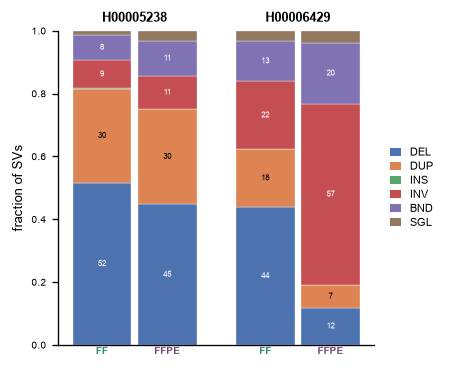

In [8]:
def draw_sv_composition(ax):
    # Stacked SV-class fractions, FF beside FFPE per patient, with in-block percentages.
    mods = list(MODALITIES); w = 0.8 / len(mods)
    tickpos, ticklab, tickcol = [], [], []
    for xi, s in enumerate(PATIENTS):
        for mi, m in enumerate(mods):
            xpos = xi + (mi - (len(mods) - 1) / 2) * w
            tickpos.append(xpos); ticklab.append(m); tickcol.append(MODALITIES[m]["color"])
            if s not in ARM[m]:
                continue
            sv = ARM[m][s]["sv"]; n = sum(sv.values()) or 1
            bottom = 0.0
            for cls in SV_ORDER:
                frac = sv.get(cls, 0) / n
                ax.bar(xpos, frac, bottom=bottom, width=w * 0.9, color=SV_COLORS[cls],
                       edgecolor="white", linewidth=0.2)
                if frac >= 0.05:
                    ax.text(xpos, bottom + frac / 2, f"{frac * 100:.0f}", ha="center", va="center",
                            fontsize=5, color=_text_color(SV_COLORS[cls]))
                bottom += frac
    ax.set_ylim(0, 1); ax.set_ylabel("fraction of SVs"); ax.tick_params(axis="y", labelsize=6)
    ax.set_xticks(tickpos); ax.set_xticklabels(ticklab, fontsize=6, fontweight="bold")
    for t, col in zip(ax.get_xticklabels(), tickcol):
        t.set_color(col)
    ax.tick_params(axis="x", length=0, pad=1)
    for xi, s in enumerate(PATIENTS):                       # patient label above each arm pair
        ax.text(xi, 1.02, s, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontsize=8, weight="bold")
    ax.legend(handles=[Patch(facecolor=SV_COLORS[c], label=c) for c in SV_ORDER],
              ncol=1, fontsize=6.5, loc="center left", bbox_to_anchor=(1.02, 0.5),
              handlelength=1.0, labelspacing=0.35)
    return [ax]

fig, ax = plt.subplots(figsize=(3.4, 3.4))
draw_sv_composition(ax)
plt.show()

## 8 · Panel C — circos and reportable-driver concordance (FF vs FFPE)

Per patient: the two PURPLE circos (FF left, FFPE right, tumour purity in the title) above an
oncoprint of that patient's reportable drivers. Genes run across and the two arms run down, so
FF↔FFPE agreement reads vertically and FFPE-only calls (candidate artefacts) show as a filled tile
in the FFPE row only. All oncoprint labels are horizontal.

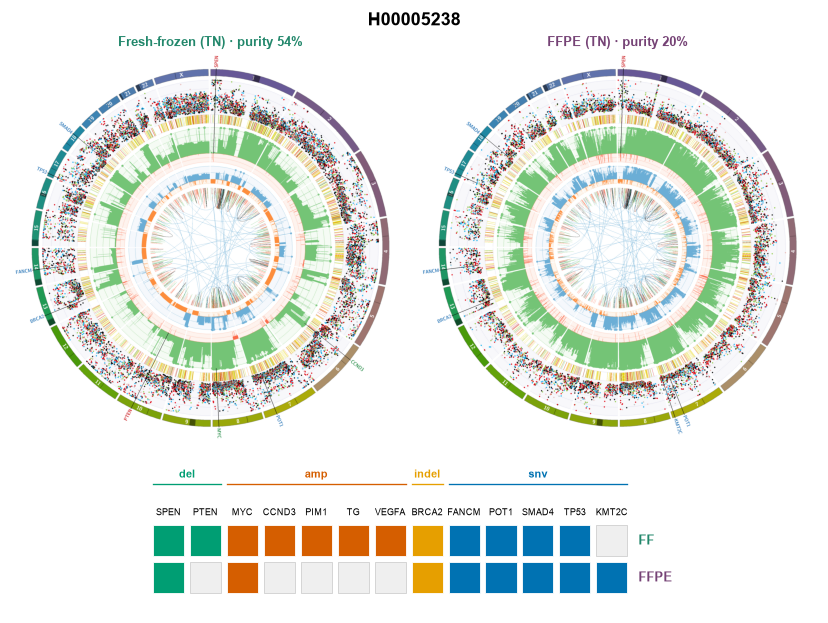

In [9]:
def _driver_columns(sid):
    # Gene columns for one patient, grouped by alteration type, shared calls first within a group.
    present = {m: ARM[m].get(sid, {}).get("drivers", set()) for m in MODALITIES}
    n_arms = lambda gc: sum(gc in present[m] for m in MODALITIES)
    cols = sorted(set().union(*present.values()),
                  key=lambda gc: (CAT_ORDER.index(gc[1]), -n_arms(gc), gc[0]))
    return cols, present

def draw_oncoprint(ax, sid):
    cols, present = _driver_columns(sid)
    for xi, (gene, cat) in enumerate(cols):
        for mi, m in enumerate(MODALITIES):
            on = (gene, cat) in present[m]
            ax.add_patch(Rectangle((xi + 0.08, -mi - 0.92), 0.84, 0.84,
                                   facecolor=CAT_COLORS[cat] if on else "#EFEFEF",
                                   edgecolor="white" if on else "#CFCFCF", lw=0.5))
        ax.text(xi + 0.5, 0.14, gene, ha="center", va="bottom", fontsize=5.5)
    i = 0
    while i < len(cols):                                  # one bracket + label per category run
        cat = cols[i][1]; j = i
        while j < len(cols) and cols[j][1] == cat:
            j += 1
        ax.plot([i + 0.08, j - 0.08], [1.05, 1.05], color=CAT_COLORS[cat], lw=0.8)
        ax.text((i + j) / 2, 1.15, cat, ha="center", va="bottom", fontsize=6.5,
                weight="bold", color=CAT_COLORS[cat])
        i = j
    for mi, m in enumerate(MODALITIES):
        ax.text(len(cols) + 0.22, -mi - 0.5, m, ha="left", va="center", fontsize=7.5,
                weight="bold", color=MODALITIES[m]["color"])
    ax.set_xlim(-0.3, len(cols) + 1.6); ax.set_ylim(-2.4, 1.9)
    ax.set_aspect("equal"); ax.axis("off")
    return ax

def _circos_title(m, sid):
    pur = ARM[m].get(sid, {}).get("purity")
    return MODALITIES[m]["label"] + (f" · purity {pur * 100:.0f}%" if pur is not None else "")

def draw_patient_block(fig, spec, sid):
    # Two circos above the shared oncoprint, as one panel-C column per patient.
    blk = spec.subgridspec(2, 1, height_ratios=[1.0, 0.40], hspace=0.02)
    circ = blk[0].subgridspec(1, len(MODALITIES), wspace=0.02)
    axes = []
    for mi, m in enumerate(MODALITIES):
        ax = fig.add_subplot(circ[0, mi]); ax.axis("off"); axes.append(ax)
        p = ARM[m].get(sid, {}).get("circos")
        if p and Path(p).exists():
            ax.imshow(mpimg.imread(p))
        else:
            ax.text(0.5, 0.5, "n/a", ha="center", va="center", transform=ax.transAxes, fontsize=8)
        ax.set_title(_circos_title(m, sid), fontsize=8, weight="bold",
                     color=MODALITIES[m]["color"], pad=2)
    return axes + [draw_oncoprint(fig.add_subplot(blk[1]), sid)]

fig = plt.figure(figsize=(7.0, 5.2))
gs = fig.add_gridspec(1, 1, left=0.02, right=0.98, top=0.92, bottom=0.02)
draw_patient_block(fig, gs[0, 0], PATIENTS[0])
fig.suptitle(PATIENTS[0], fontsize=11, weight="bold")
plt.show()

## 9 · Panel D — variant burden (Illumina TN vs TO)

Tumour/normal in full colour beside tumour-only. For SNV, MNV and indel the tumour-only bar is
stacked by the per-variant **somatic likelihood** (`SOM_LH` ∈ {HIGH, MEDIUM, LOW}) that PURPLE
assigns in tumour-only mode, in shades of the Illumina orange (dark = HIGH): the excess over tumour/normal should
sit in the MEDIUM / LOW bins if it is germline leakage. Tumour/normal calls carry no `SOM_LH`, and
SV and CNA have none either, so those bars stay plain.

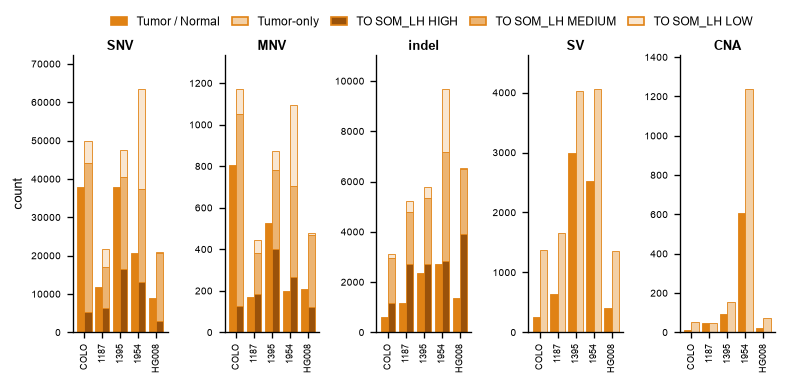

In [10]:
def _blank(fig, spec, msg):
    ax = fig.add_subplot(spec); ax.axis("off")
    ax.text(0.5, 0.5, msg, ha="center", va="center", fontsize=8, color="#999",
            transform=ax.transAxes)
    return [ax]

def _somlh_split(cond, vt):
    # Stack a bar by SOM_LH only where that condition's calls actually carry it (tumour-only).
    return any(lh != "NA" and n for s in CELL[cond].values() if vt in s.get("somlh", {})
               for lh, n in s["somlh"][vt].items())

def burden_cmp_handles():
    # Condition swatches, then the SOM_LH bins present in any stacked panel D bar.
    hs = [Patch(facecolor=_cond_face(ILLUMINA_COLOR, c), edgecolor=ILLUMINA_COLOR,
                label=CONDITIONS[c]["label"]) for c in CONDITIONS]
    present = [lh for lh in SOMLH_STACK
               if any(_somlh_split(c, vt) and s["somlh"][vt].get(lh, 0)
                      for c in CONDITIONS for s in CELL[c].values() for vt in s["somlh"])]
    return hs + [Patch(facecolor=SOMLH_COLORS[lh], edgecolor=ILLUMINA_COLOR,
                       label=f"TO SOM_LH {lh}") for lh in present]

def draw_burden_cmp(fig, spec):
    # Illumina only: tumour/normal in full colour beside tumour-only as a light tint.
    if not CELL_LINES:
        return _blank(fig, spec, "Illumina cell-line runs not available")
    conds = list(CONDITIONS); w = 0.8 / len(conds)
    x = np.arange(len(CELL_LINES))
    sub = spec.subgridspec(1, len(VAR_TYPES), wspace=0.60)
    axes = []
    for k, vt in enumerate(VAR_TYPES):
        ax = fig.add_subplot(sub[0, k])
        for ci, cond in enumerate(conds):
            xs = x + (ci - (len(conds) - 1) / 2) * w
            vals = [CELL[cond][c]["counts"].get(vt, np.nan) if c in CELL[cond] else np.nan
                    for c in CELL_LINES]
            if not _somlh_split(cond, vt):
                ax.bar(xs, vals, w, color=_cond_face(ILLUMINA_COLOR, cond),
                       edgecolor=ILLUMINA_COLOR, linewidth=0.5, zorder=2)
                continue
            bottom = np.zeros(len(CELL_LINES))       # tumour-only: stacked by SOM_LH
            for lh in SOMLH_STACK:
                h = np.array([CELL[cond][c]["somlh"][vt].get(lh, 0) if c in CELL[cond] else 0
                              for c in CELL_LINES], dtype=float)
                if h.any():
                    ax.bar(xs, h, w, bottom=bottom, color=SOMLH_COLORS[lh],
                           edgecolor=ILLUMINA_COLOR, linewidth=0.5, zorder=2)
                bottom += h
        ax.set_title(vt, fontsize=7.5, pad=3)
        ax.set_xticks(x); ax.set_xticklabels([_short(c) for c in CELL_LINES],
                                             fontsize=5.6, rotation=90)
        ax.tick_params(axis="y", labelsize=6); ax.margins(y=0.14)
        axes.append(ax)
    axes[0].set_ylabel("count")
    return axes

fig = plt.figure(figsize=(6.5, 3.4))
draw_burden_cmp(fig, fig.add_gridspec(1, 1, left=0.09, right=0.99, top=0.90, bottom=0.22)[0, 0])
_h = burden_cmp_handles()
fig.legend(handles=_h, loc="upper center", bbox_to_anchor=(0.55, 1.02), ncol=len(_h),
           fontsize=7, handlelength=1.4, columnspacing=1.0)
plt.show()

## 10 · Panel E — SV class composition (Illumina TN vs TO)

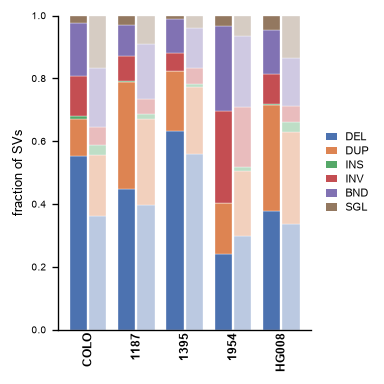

In [10]:
def draw_sv_cmp(fig, spec):
    # Stacked SV-class fractions per cell line, tumour/normal beside tumour-only (tinted).
    if not CELL_LINES:
        return _blank(fig, spec, "Illumina cell-line runs not available")
    ax = fig.add_subplot(spec)
    conds = list(CONDITIONS); w = 0.8 / len(conds)
    for xi, c in enumerate(CELL_LINES):
        for ci, cond in enumerate(conds):
            if c not in CELL[cond]:
                continue
            xpos = xi + (ci - (len(conds) - 1) / 2) * w
            sv = CELL[cond][c]["sv"]; n = sum(sv.values()) or 1
            bottom = 0.0
            for cls in SV_ORDER:
                frac = sv.get(cls, 0) / n
                ax.bar(xpos, frac, bottom=bottom, width=w * 0.9,
                       color=_cond_face(SV_COLORS[cls], cond), edgecolor="white", linewidth=0.2)
                bottom += frac
    ax.set_ylim(0, 1); ax.set_ylabel("fraction of SVs"); ax.tick_params(axis="y", labelsize=6)
    ax.set_xticks(np.arange(len(CELL_LINES)))
    ax.set_xticklabels([_short(c) for c in CELL_LINES], fontsize=7, rotation=90, fontweight="bold")
    ax.tick_params(axis="x", length=0, pad=2)
    ax.legend(handles=[Patch(facecolor=SV_COLORS[c], label=c) for c in SV_ORDER],
              ncol=1, fontsize=6.5, loc="center left", bbox_to_anchor=(1.02, 0.5),
              handlelength=1.0, labelspacing=0.35)
    return [ax]

fig = plt.figure(figsize=(3.4, 3.4))
draw_sv_cmp(fig, fig.add_gridspec(1, 1, left=0.18, right=0.80, top=0.95, bottom=0.18)[0, 0])
plt.show()

## 11 · Composite figure

In [1]:
def composite_figure():
    fig = plt.figure(figsize=(16.0, 15.0))
    outer = fig.add_gridspec(3, 1, height_ratios=[1.0, 2.4, 1.0], hspace=0.30,
                             left=0.050, right=0.955, top=0.940, bottom=0.035)
    top = outer[0].subgridspec(1, 2, width_ratios=[2.6, 1.0], wspace=0.32)
    axA = draw_burden(fig, top[0, 0])
    axB = fig.add_subplot(top[0, 1]); draw_sv_composition(axB)

    mid = outer[1].subgridspec(1, len(PATIENTS), wspace=0.10)
    blocks = {sid: draw_patient_block(fig, mid[0, pi], sid) for pi, sid in enumerate(PATIENTS)}

    bot = outer[2].subgridspec(1, 2, width_ratios=[2.6, 1.0], wspace=0.32)
    axD = draw_burden_cmp(fig, bot[0, 0])
    axE = draw_sv_cmp(fig, bot[0, 1])

    fig.canvas.draw()
    def _title(group, text, dy=0.014):
        p = group[0].get_position()
        fig.text(p.x0, p.y1 + dy, text, fontsize=10.5, weight="bold", ha="left", va="bottom")
        return p
    tag = f" (VAF ≥ {round(VAF_MIN * 100)}%)"
    pa = _title(axA, "A · variant burden" + tag, dy=0.020)
    _title([axB], "B · SV class composition")
    _title(axD, "D · variant burden — Illumina TN vs TO" + tag, dy=0.020)
    _title(axE, "E · SV class composition — Illumina TN vs TO")
    for sid, group in blocks.items():                       # patient id above each panel C column
        p = group[0].get_position()
        fig.text(p.x0, p.y1 + 0.012, sid, fontsize=11, weight="bold", ha="left", va="bottom")
    pc = blocks[PATIENTS[0]][0].get_position()
    fig.text(0.050, pc.y1 + 0.030, "C · circos and reportable-driver concordance",
             fontsize=10.5, weight="bold", ha="left", va="bottom")

    fig.legend(handles=[Line2D([0], [0], marker="s", ls="", ms=8, color=MODALITIES[m]["color"],
                               label=MODALITIES[m]["label"]) for m in MODALITIES],
               loc="lower left", bbox_to_anchor=(pa.x0 + 0.22, pa.y1 + 0.018), ncol=2, fontsize=8.5,
               handletextpad=0.3, columnspacing=1.2)
    pdd = axD[0].get_position()
    _h = burden_cmp_handles()
    fig.legend(handles=_h, loc="lower left", bbox_to_anchor=(pdd.x0 + 0.25, pdd.y1 + 0.018),
               ncol=len(_h),
               fontsize=8.5, handlelength=1.4, handletextpad=0.4, columnspacing=1.2)
    return fig

fig = composite_figure()
stem = EXPORT_DIR / "figure_3"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()

NameError: name 'plt' is not defined